*Inspirado en: [moloxe.com/blog/transformada-discreta-de-fourier-dft-en-javascript/#fft](https://moloxe.com/blog/transformada-discreta-de-fourier-dft-en-javascript/#fft)*

# 🔬 Experimento 2026-10: Carga Progresiva por Fourier (Codificación 1D y Decodificación Progresiva)
**Proyecto:** `<mx-img />` - Carga Progresiva de Imágenes por Secuencia de Frecuencias

## Contexto y Evolución del Experimento
En el experimento previo ([`2026-10-new-format-01.ipynb`](2026-10-new-format-01.ipynb)), simulamos la carga progresiva aplicando una **máscara circular 2D** directamente sobre el espectro de Fourier centrado. Si bien demostró visualmente el principio del filtro paso bajo, mantener una matriz 2D y una máscara sintética no refleja cómo se transmiten los datos a través de la red en un escenario real de streaming.

En esta etapa evolucionamos hacia una arquitectura real de **streaming espectral**:
1. **Codificación 1D (Encoding):** La imagen 2D se transforma al dominio de Fourier y sus coeficientes complejos se serializan en un **único arreglo unidimensional continuo** ($1D$), ordenado estrictamente por prioridad frecuencial concéntrica: desde la componente continua (DC, frecuencia cero) y frecuencias ultrabajas, pasando por frecuencias medias, hasta las frecuencias más altas en las esquinas.
2. **Decodificación Progresiva (Decoding):** El cliente recibe únicamente fragmentos o prefijos de la secuencia (`secuencia[:K]`). Conociendo únicamente las dimensiones $(H, W)$ de la imagen, el decodificador genera de manera determinista e implícita las coordenadas correspondientes a cada coeficiente sin requerir metadatos ni tablas de posiciones adicionales, permitiendo reconstruir la imagen en tiempo real a medida que fluyen los datos.

In [10]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from functools import lru_cache

# Configuración visual
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'

# Ubicación de la imagen de prueba (búsqueda robusta compatible con cualquier entorno o CWD)
candidate_paths = [
    '../images/image.jpeg',
    'images/image.jpeg',
    'experiments/images/image.jpeg',
    '/Users/francomolochegarcia/dev/mx-img/experiments/images/image.jpeg'
]
img_path = next((p for p in candidate_paths if os.path.exists(p)), None)
assert img_path is not None, f"No se encontró la imagen en ninguna ruta: {candidate_paths}"
print(f"✅ Entorno preparado y archivo verificado: {img_path}")

✅ Entorno preparado y archivo verificado: ../images/image.jpeg


## 🧭 Paso 1: Generación del Mapa de Ordenamiento Radial (Implícito)

Para que el codificador y el decodificador sincronicen exactamente qué coeficiente corresponde a qué celda frecuencial del espectro 2D **sin transmitir metadatos de coordenadas**, definimos una función determinista que solo requiere las dimensiones $(H, W)$:

1. **Centro espectral:** $(c_y, c_x) = (\lfloor H/2 
floor, \lfloor W/2 
floor)$.
2. **Distancia euclidiana al cuadrado:** Para cada celda $(y, x)$:
   $$d^2(y, x) = (y - c_y)^2 + (x - c_x)^2$$
3. **Criterio de desempate:** En caso de empate en distancia (puntos sobre la misma circunferencia), utilizamos su ángulo polar:
   $$\theta(y, x) = \operatorname{atan2}(y - c_y, x - c_x) \in [-\pi, \pi]$$
4. **Orden lexicográfico:** Mediante `np.lexsort((theta.ravel(), dist_sq.ravel()))`, obtenemos el vector de índices 1D `orden_radial` que recorre la matriz desde el centro exacto (DC, donde $d^2=0$) hacia los bordes en anillos concéntricos continuos.
5. **Cero overhead de red:** Tanto el transmisor como el receptor deducen este orden idéntico a partir exclusivamente de $(H, W)$.

📐 Dimensiones probadas: 780x800 (624,000 elementos)
🎯 Índice del primer elemento (DC): 312400 (Esperado: 312400) -> ✅ Correcto
🔄 Distancia radial estrictamente monótona creciente: ✅ Sí


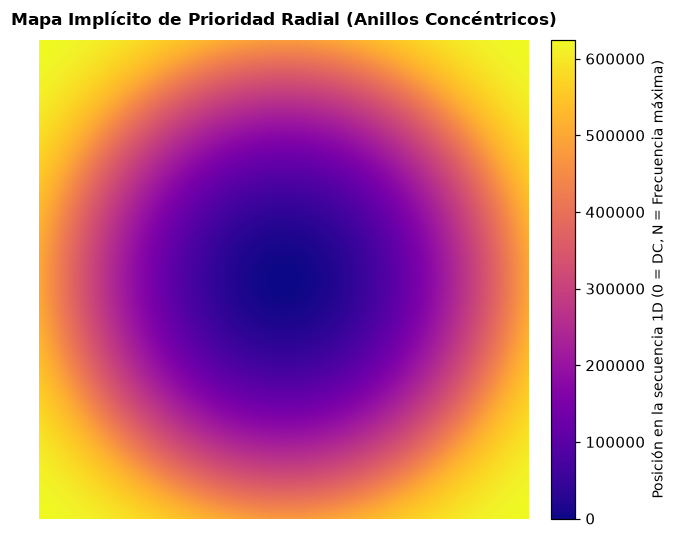

In [11]:
@lru_cache(maxsize=16)
def generar_orden_radial(h: int, w: int) -> np.ndarray:
    """
    Genera el vector de índices 1D determinista para ordenar una matriz (h, w)
    desde la componente DC central (h//2, w//2) hacia el exterior en anillos concéntricos.
    
    Criterio primario: Distancia euclidiana al cuadrado respecto al centro.
    Criterio de desempate: Ángulo polar theta en [-pi, pi].
    """
    cy, cx = h // 2, w // 2
    y, x = np.ogrid[:h, :w]
    dist_sq = (y - cy)**2 + (x - cx)**2
    theta = np.arctan2(y - cy, x - cx)
    
    # lexsort ordena por la última clave primero (dist_sq) y desempata con theta
    orden_radial = np.lexsort((theta.ravel(), dist_sq.ravel()))
    return orden_radial

# Verificación de propiedades matemáticas del ordenamiento
h_test, w_test = 780, 800
orden_test = generar_orden_radial(h_test, w_test)
cy_test, cx_test = h_test // 2, w_test // 2
idx_dc_esperado = cy_test * w_test + cx_test

print(f"📐 Dimensiones probadas: {h_test}x{w_test} ({h_test * w_test:,} elementos)")
print(f"🎯 Índice del primer elemento (DC): {orden_test[0]} (Esperado: {idx_dc_esperado}) -> {'✅ Correcto' if orden_test[0] == idx_dc_esperado else '❌ Error'}")

# Comprobación de monotonía en las distancias
y_g, x_g = np.ogrid[:h_test, :w_test]
dist_test = ((y_g - cy_test)**2 + (x_g - cx_test)**2).ravel()
es_monotono = np.all(dist_test[orden_test[:-1]] <= dist_test[orden_test[1:]])
print(f"🔄 Distancia radial estrictamente monótona creciente: {'✅ Sí' if es_monotono else '❌ No'}")

# Visualización del mapa implícito de prioridad radial (anillos concéntricos)
rank_map = np.empty(h_test * w_test, dtype=np.int32)
rank_map[orden_test] = np.arange(h_test * w_test)
rank_2d = rank_map.reshape((h_test, w_test))

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(rank_2d, cmap='plasma')
ax.set_title("Mapa Implícito de Prioridad Radial (Anillos Concéntricos)", fontsize=11, fontweight='bold', pad=10)
ax.axis('off')
cbar = fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Posición en la secuencia 1D (0 = DC, N = Frecuencia máxima)", fontsize=9)
plt.tight_layout()
plt.show()

## 📦 Paso 2: Función de Encoding (Imagen 2D $	o$ Secuencia 1D)

La función de codificación toma la imagen espacial 2D y la convierte en una secuencia unidimensional continua:
1. **FFT 2D + Centrado:**
   $$F_{\text{shift}}(u, v) = \text{fftshift}\left(\mathcal{F}\{f(x, y)\}\right)$$
2. **Generación del orden radial:** Obtiene `orden_radial` a partir de las dimensiones $(H, W)$.
3. **Serialización por prioridad:** Aplana el espectro 2D y lo indexa con `orden_radial`:
   $$\text{secuencia}_{1D} = F_{\text{shift\_flat}}[\text{orden\_radial}]$$

**Salida:** Un único arreglo 1D de números complejos (`np.complex128`) ordenados secuencialmente por prioridad frecuencial, junto con la tupla de dimensiones $(H, W)$.

In [12]:
def encode_fourier_1d(img: np.ndarray) -> tuple[np.ndarray, tuple[int, int]]:
    """
    Codifica una imagen 2D en escala de grises a una secuencia 1D de coeficientes
    complejos de Fourier ordenados por prioridad frecuencial concéntrica.
    
    Parámetros:
        img: Matriz 2D de la imagen en escala de grises (uint8 o float).
        
    Retorna:
        secuencia_1d: Arreglo 1D de coeficientes complejos (complex128) ordenados por prioridad.
        (h, w): Tupla con las dimensiones originales de la imagen.
    """
    h, w = img.shape
    
    # 1. Transformada de Fourier 2D y desplazamiento al centro (frecuencia cero al centro)
    f_transform = np.fft.fft2(img.astype(np.float64))
    f_shift = np.fft.fftshift(f_transform)
    
    # 2. Vector determinista de ordenamiento radial implícito
    orden = generar_orden_radial(h, w)
    
    # 3. Aplanar el espectro 2D y reordenar según orden_radial
    secuencia_1d = f_shift.ravel()[orden]
    
    return secuencia_1d, (h, w)

## 🧩 Paso 3: Función de Decoding Progresivo (Secuencia 1D Parcial $	o$ Imagen Renderizable)

La función de decodificación progresiva reconstruye la imagen a partir de un prefijo cualquiera $\text{secuencia}[:K]$ ($K \le N$):
1. **Deducción de coordenadas:** Con solo conocer $(H, W)$, el decodificador genera el mismo vector `orden_radial`.
2. **Inicialización de buffer:** Crea un arreglo 1D de ceros complejos de tamaño $H \times W$.
3. **Inyección de coeficientes:** Inserta los $K$ coeficientes recibidos en las posiciones `orden_radial[:K]`.
4. **Matriz espectral parcial:** Redimensiona el buffer 1D a $(H, W)$.
5. **IFFT 2D:** Invierte el centrado (`ifftshift`) y calcula la transformada inversa de Fourier 2D (`ifft2`).
6. **Extracción y normalización:** Toma la parte real acotada al rango $[0, 255]$ en formato `uint8`.

**Salida:** La imagen 2D reconstruida lista para renderizar y la matriz 2D del espectro parcial reconstruido.

In [13]:
def decode_fourier_progresivo(secuencia_parcial: np.ndarray, shape_original: tuple[int, int]) -> tuple[np.ndarray, np.ndarray]:
    """
    Decodifica progresivamente un segmento/prefijo 1D de coeficientes de Fourier
    a una imagen 2D renderizable en el espacio espacial.
    
    Parámetros:
        secuencia_parcial: Prefijo de K coeficientes complejos (secuencia[:K]).
        shape_original: Dimensiones originales (H, W).
        
    Retorna:
        img_reconstruida: Imagen 2D lista para renderizar (uint8 [0, 255]).
        espectro_2d_parcial: Matriz 2D del espectro complejo parcial reconstruido.
    """
    h, w = shape_original
    k = len(secuencia_parcial)
    
    # 1. Generar vector de orden radial implícito a partir de (h, w)
    orden = generar_orden_radial(h, w)
    
    # 2. Inicializar arreglo 1D de ceros complejos
    espectro_1d = np.zeros(h * w, dtype=np.complex128)
    
    # 3. Insertar los K coeficientes en las posiciones correspondientes
    espectro_1d[orden[:k]] = secuencia_parcial
    
    # 4. Redimensionar a la matriz 2D del espectro parcial
    espectro_2d_parcial = espectro_1d.reshape((h, w))
    
    # 5. Revertir desplazamiento central y aplicar IFFT 2D
    f_ishift = np.fft.ifftshift(espectro_2d_parcial)
    img_back = np.fft.ifft2(f_ishift)
    
    # 6. Extraer magnitud real normalizada/recortada a rango uint8 [0, 255]
    img_reconstruida = np.clip(np.real(img_back), 0, 255).astype(np.uint8)
    
    return img_reconstruida, espectro_2d_parcial

## 📊 Paso 4: Demostración y Evidencia de Serialización

A continuación realizamos la demostración práctica con la imagen de prueba:
1. **Carga y renderizado** de la imagen original en escala de grises indicando sus dimensiones exactas.
2. **Ejecución de encoding:** Inspección de forma, longitud total y tipo de dato (`dtype`).
3. **Análisis de magnitud de coeficientes:** Comparación entre los primeros elementos (componente DC y frecuencias bajas), intermedios y finales para evidenciar la fuerte concentración de energía en las bajas frecuencias y la caída abrupta de magnitud a lo largo de la secuencia 1D.

🖼️ Imagen de prueba cargada: ../images/image.jpeg
📏 Dimensiones: 800 × 780 píxeles (Ancho × Alto) | Total píxeles: 624,000


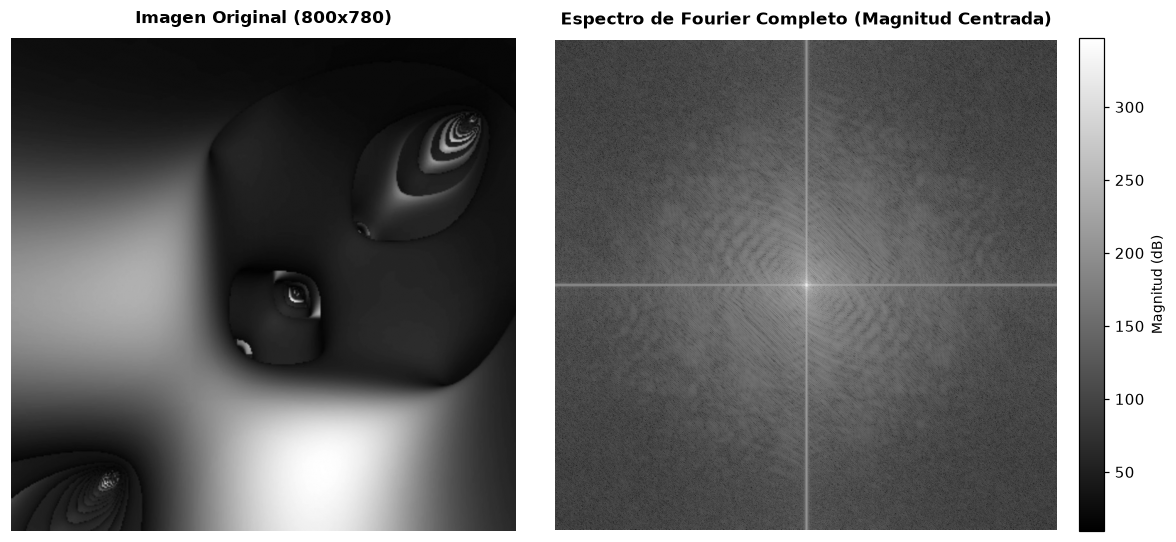

In [14]:
# Carga de la imagen de prueba en escala de grises
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
h, w = img.shape

# Espectro completo de referencia
f_full = np.fft.fftshift(np.fft.fft2(img.astype(np.float64)))
mag_full = 20 * np.log(1 + np.abs(f_full))

print(f"🖼️ Imagen de prueba cargada: {img_path}")
print(f"📏 Dimensiones: {w} × {h} píxeles (Ancho × Alto) | Total píxeles: {h * w:,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(img, cmap='gray')
axes[0].set_title(f"Imagen Original ({w}x{h})", fontsize=11, fontweight='bold', pad=10)
axes[0].axis('off')

cax = axes[1].imshow(mag_full, cmap='gray')
axes[1].set_title("Espectro de Fourier Completo (Magnitud Centrada)", fontsize=11, fontweight='bold', pad=10)
axes[1].axis('off')
cbar = fig.colorbar(cax, ax=axes[1], fraction=0.046, pad=0.04)
cbar.set_label("Magnitud (dB)", fontsize=9)

plt.tight_layout()
plt.show()

📦 EVIDENCIA DE SERIALIZACIÓN (ENCODING 1D)
• Forma del arreglo 1D (shape) : (624000,)
• Longitud total (N)           : 624,000 coeficientes
• Tipo de dato (dtype)         : complex128
• Dimensiones registradas      : 800 × 780 (W × H)
• Memoria en RAM               : 9.52 MB

🔍 MUESTRA 1: Primeros 8 elementos (DC y frecuencias ultrabajas)
Índice   Parte Real       Parte Imag       Magnitud         Prioridad
---------------------------------------------------------------------------
[     0]     34333239.00            0.00j     34333239.00  ⭐ Componente DC (Frecuencia Cero)
[     1]     -1275245.36     -9199044.62j      9287016.35  Baja frecuencia 1
[     2]     -3501615.16     -2193128.05j      4131721.12  Baja frecuencia 2
[     3]     -1275245.36      9199044.62j      9287016.35  Baja frecuencia 3
[     4]     -3501615.16      2193128.05j      4131721.12  Baja frecuencia 4
[     5]     -7692807.07     -3125379.41j      8303449.71  Baja frecuencia 5
[     6]     -2415381.47     111388

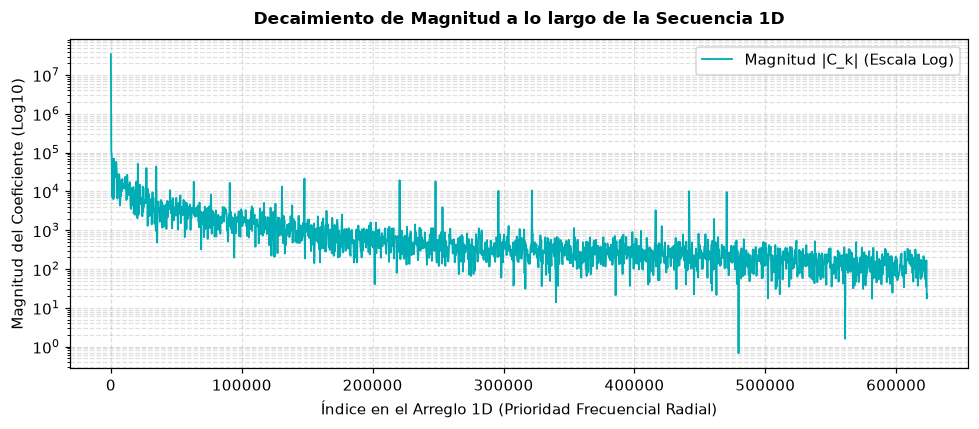

In [15]:
# Ejecución del encoding 1D
secuencia_1d, dims = encode_fourier_1d(img)
n_total = len(secuencia_1d)
magnitudes_1d = np.abs(secuencia_1d)

print("=" * 75)
print("📦 EVIDENCIA DE SERIALIZACIÓN (ENCODING 1D)")
print("=" * 75)
print(f"• Forma del arreglo 1D (shape) : {secuencia_1d.shape}")
print(f"• Longitud total (N)           : {n_total:,} coeficientes")
print(f"• Tipo de dato (dtype)         : {secuencia_1d.dtype}")
print(f"• Dimensiones registradas      : {dims[1]} × {dims[0]} (W × H)")
print(f"• Memoria en RAM               : {secuencia_1d.nbytes / (1024 * 1024):.2f} MB")
print("=" * 75)

# Muestras de coeficientes
print("\n🔍 MUESTRA 1: Primeros 8 elementos (DC y frecuencias ultrabajas)")
print(f"{'Índice':<8} {'Parte Real':<16} {'Parte Imag':<16} {'Magnitud':<16} {'Prioridad'}")
print("-" * 75)
for i in range(8):
    desc = "⭐ Componente DC (Frecuencia Cero)" if i == 0 else f"Baja frecuencia {i}"
    print(f"[{i:6d}] {secuencia_1d[i].real:15.2f} {secuencia_1d[i].imag:15.2f}j {magnitudes_1d[i]:15.2f}  {desc}")

mid_idx = n_total // 2
print(f"\n🔍 MUESTRA 2: Elementos intermedios (frecuencias medias en índice ~{mid_idx:,})")
print(f"{'Índice':<8} {'Parte Real':<16} {'Parte Imag':<16} {'Magnitud':<16}")
print("-" * 75)
for i in range(mid_idx, mid_idx + 5):
    print(f"[{i:6d}] {secuencia_1d[i].real:15.2f} {secuencia_1d[i].imag:15.2f}j {magnitudes_1d[i]:15.2f}")

print(f"\n🔍 MUESTRA 3: Elementos finales (frecuencias más altas en esquinas, últimos 5)")
print(f"{'Índice':<8} {'Parte Real':<16} {'Parte Imag':<16} {'Magnitud':<16}")
print("-" * 75)
for i in range(n_total - 5, n_total):
    print(f"[{i:6d}] {secuencia_1d[i].real:15.2f} {secuencia_1d[i].imag:15.2f}j {magnitudes_1d[i]:15.2f}")

# Caída de magnitud relativa
caida_dc_a_mid = magnitudes_1d[0] / (np.mean(magnitudes_1d[mid_idx:mid_idx+100]) + 1e-10)
caida_dc_a_fin = magnitudes_1d[0] / (np.mean(magnitudes_1d[-100:]) + 1e-10)
print("\n📉 CAÍDA DE MAGNITUD ESPECTRAL:")
print(f"• Caída de magnitud DC -> Frecuencias Medias : ~{caida_dc_a_mid:,.0f}x veces menor")
print(f"• Caída de magnitud DC -> Altas Frecuencias   : ~{caida_dc_a_fin:,.0f}x veces menor")

# Gráfica de decaimiento espectral (ley de potencias)
fig, ax = plt.subplots(figsize=(9, 4))
submuestreo = max(1, n_total // 2000)
x_plot = np.arange(0, n_total, submuestreo)
y_plot = magnitudes_1d[::submuestreo]

ax.semilogy(x_plot, y_plot, color='#00adb5', lw=1.2, label='Magnitud |C_k| (Escala Log)')
ax.set_title("Decaimiento de Magnitud a lo largo de la Secuencia 1D", fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel("Índice en el Arreglo 1D (Prioridad Frecuencial Radial)", fontsize=10)
ax.set_ylabel("Magnitud del Coeficiente (Log10)", fontsize=10)
ax.grid(True, which="both", ls="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

## 🎛️ Paso 5: Bloque Interactivo de Carga Progresiva Secuencial

Implementamos la cuadrícula comparativa $2\times 2$ según los requerimientos del proyecto:
1. **Superior izquierda:** Espectro de magnitud completo.
2. **Superior derecha:** Imagen original.
3. **Inferior izquierda:** Espectro parcial reconstruido exclusivamente desde el corte `secuencia[:K]`.
4. **Inferior derecha:** Imagen resultante de la función de decoding progresivo.

El encabezado muestra en tiempo real:
- **Porcentaje de la secuencia leída**
- **Cantidad de coeficientes decodificados ($K$ de $N$)**
- **Fidelidad métrica PSNR (Peak Signal-to-Noise Ratio)**

In [16]:
def render_progression_2x2(progreso):
    """
    Renderiza la cuadrícula comparativa 2x2 para un nivel de progreso dado
    (soporta porcentaje 0.01 - 100% o cantidad absoluta de coeficientes K).
    """
    # Determinación flexible de K
    if isinstance(progreso, (int, float)):
        if progreso <= 1.0:
            pct = progreso * 100.0
            k = max(1, int(n_total * progreso))
        elif progreso <= 100.0:
            pct = float(progreso)
            k = max(1, int(n_total * (pct / 100.0)))
        else:
            k = min(n_total, max(1, int(progreso)))
            pct = (k / n_total) * 100.0
    else:
        pct = 100.0
        k = n_total
        
    k = min(n_total, max(1, k))
    
    # Decodificación a partir únicamente del prefijo recibido secuencia_1d[:k]
    img_rec, espectro_parcial = decode_fourier_progresivo(secuencia_1d[:k], dims)
    
    # Magnitud logarítmica del espectro parcial
    mag_parcial = 20 * np.log(1 + np.abs(espectro_parcial))
    
    # Métricas de error y calidad de imagen
    mse = np.mean((img.astype(float) - img_rec.astype(float))**2)
    psnr = 10 * np.log10((255.0**2) / (mse + 1e-10))
    
    # Cuadrícula 2x2 con estética uniforme de alto contraste
    fig, axes = plt.subplots(2, 2, figsize=(9, 9), facecolor='black')
    
    # 1. Superior izquierda: Espectro completo
    axes[0, 0].imshow(mag_full, cmap='gray')
    axes[0, 0].axis('off')
    
    # 2. Superior derecha: Imagen original
    axes[0, 1].imshow(img, cmap='gray')
    axes[0, 1].axis('off')
    
    # 3. Inferior izquierda: Espectro parcial reconstruido desde secuencia[:K]
    axes[1, 0].imshow(mag_parcial, cmap='gray', vmin=0, vmax=np.max(mag_full))
    axes[1, 0].axis('off')
    
    # 4. Inferior derecha: Imagen decodificada
    axes[1, 1].imshow(img_rec, cmap='gray')
    axes[1, 1].axis('off')
    
    fig.subplots_adjust(wspace=0.01, hspace=0.01, left=0, right=1, bottom=0, top=1)
    plt.suptitle(f"Secuencia: {pct:6.2f}% | Coeficientes K: {k:,} de {n_total:,} | PSNR: {psnr:5.2f} dB",
                 color='white', fontsize=12, y=0.99)
    plt.show()
    return img_rec, psnr

🚀 Generando evidencia visual multi-etapa de la carga progresiva:


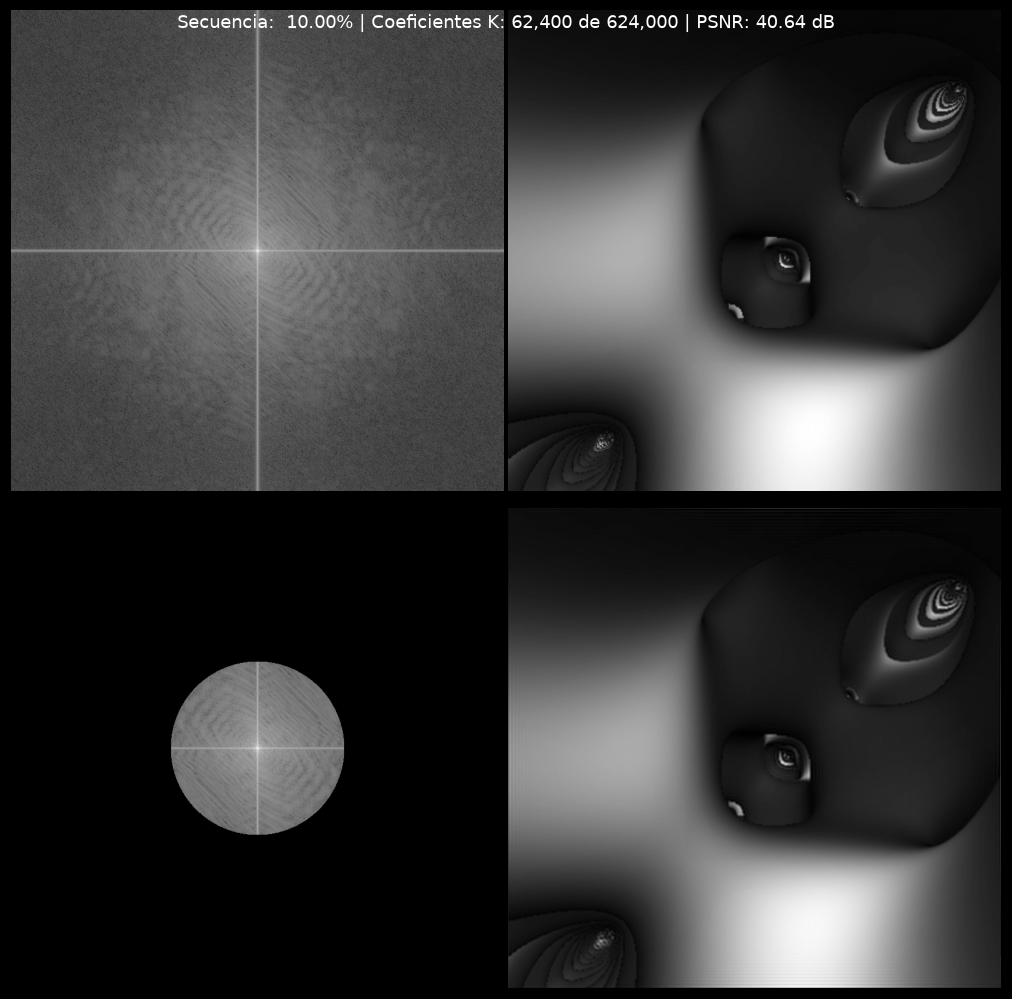

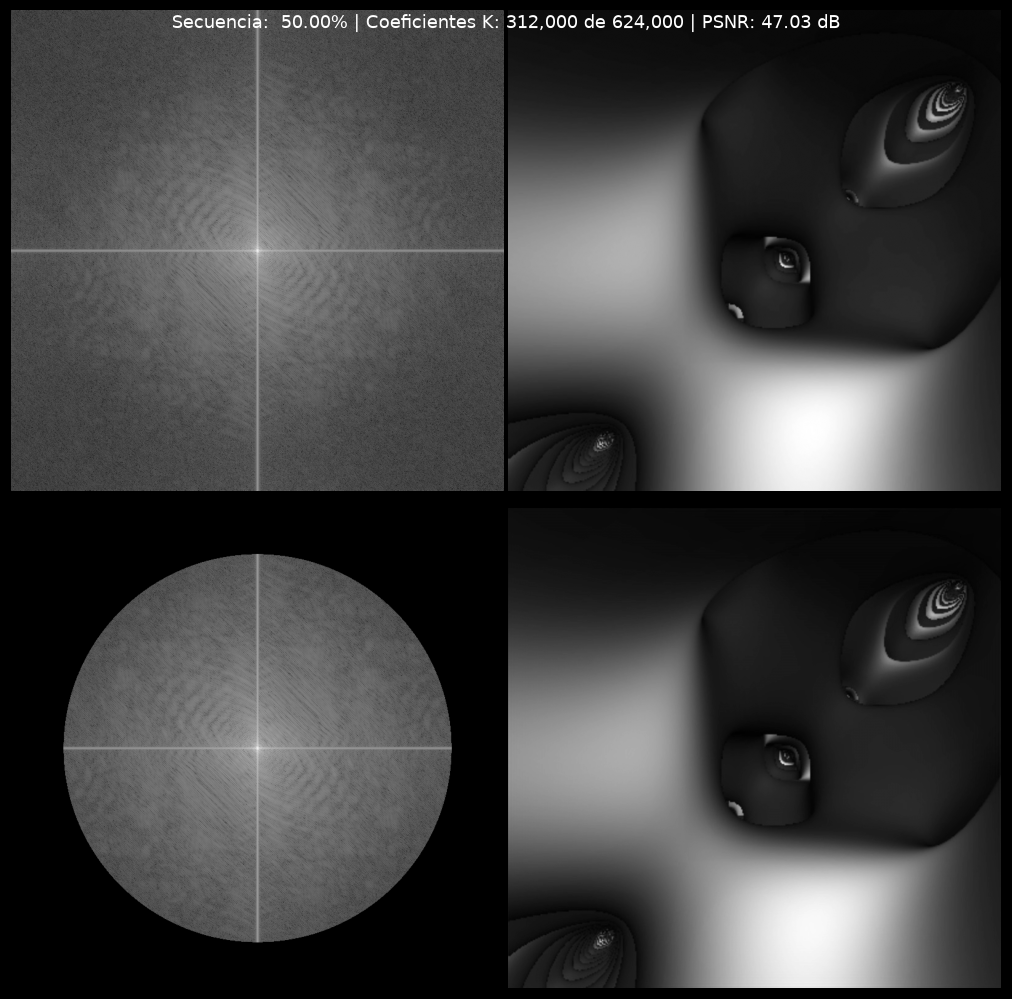

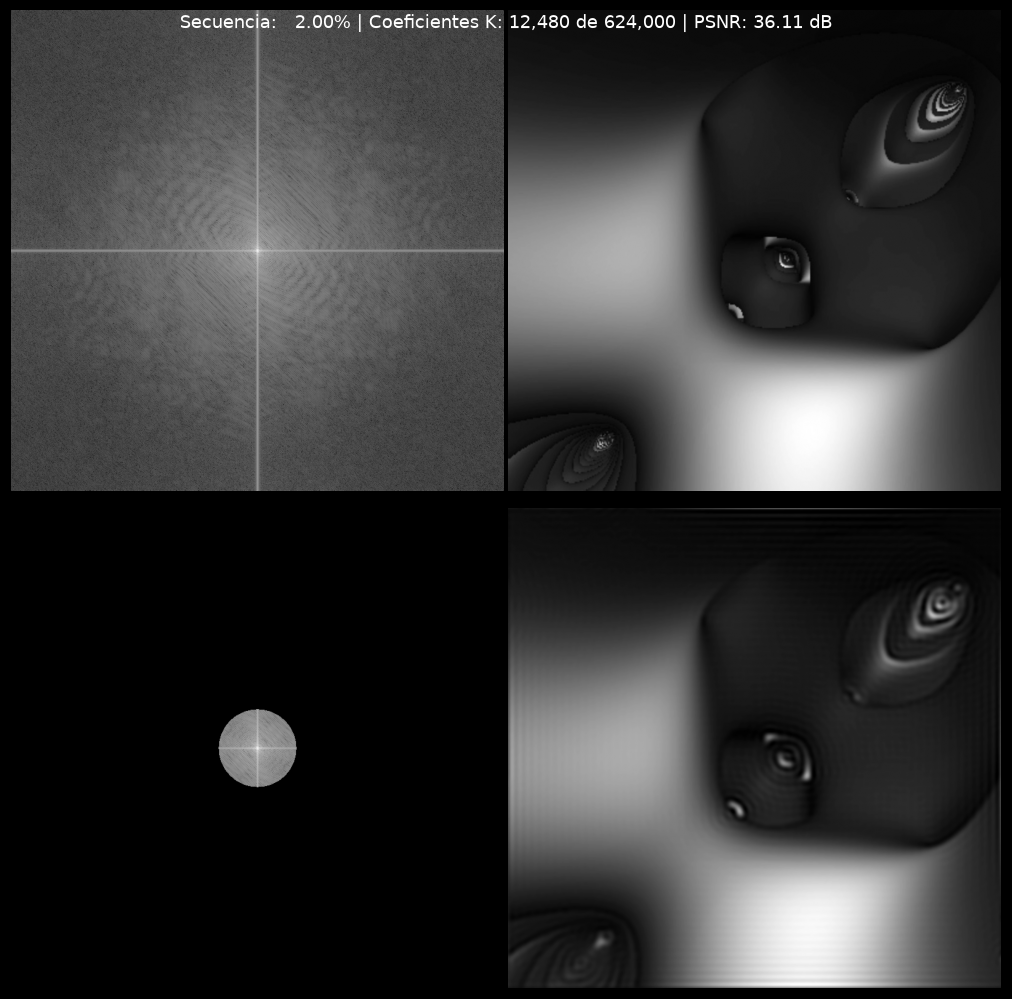

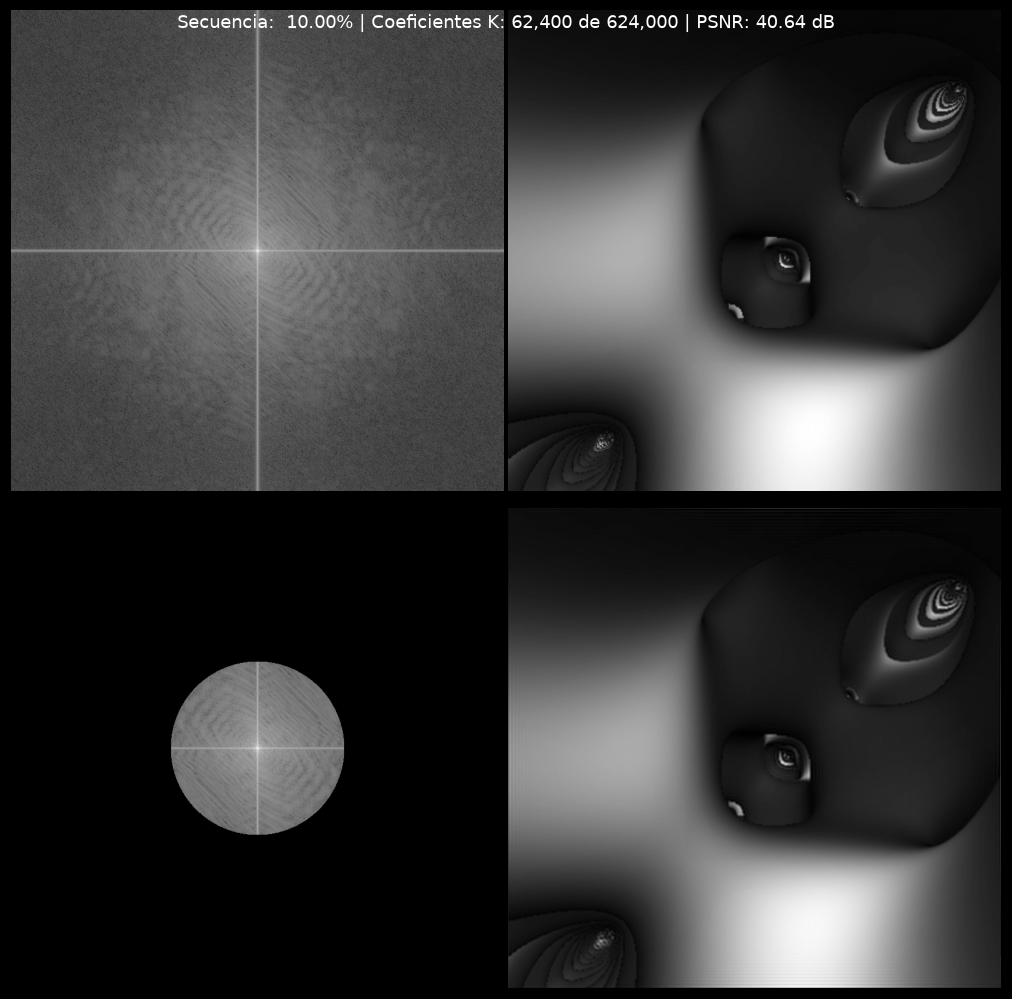

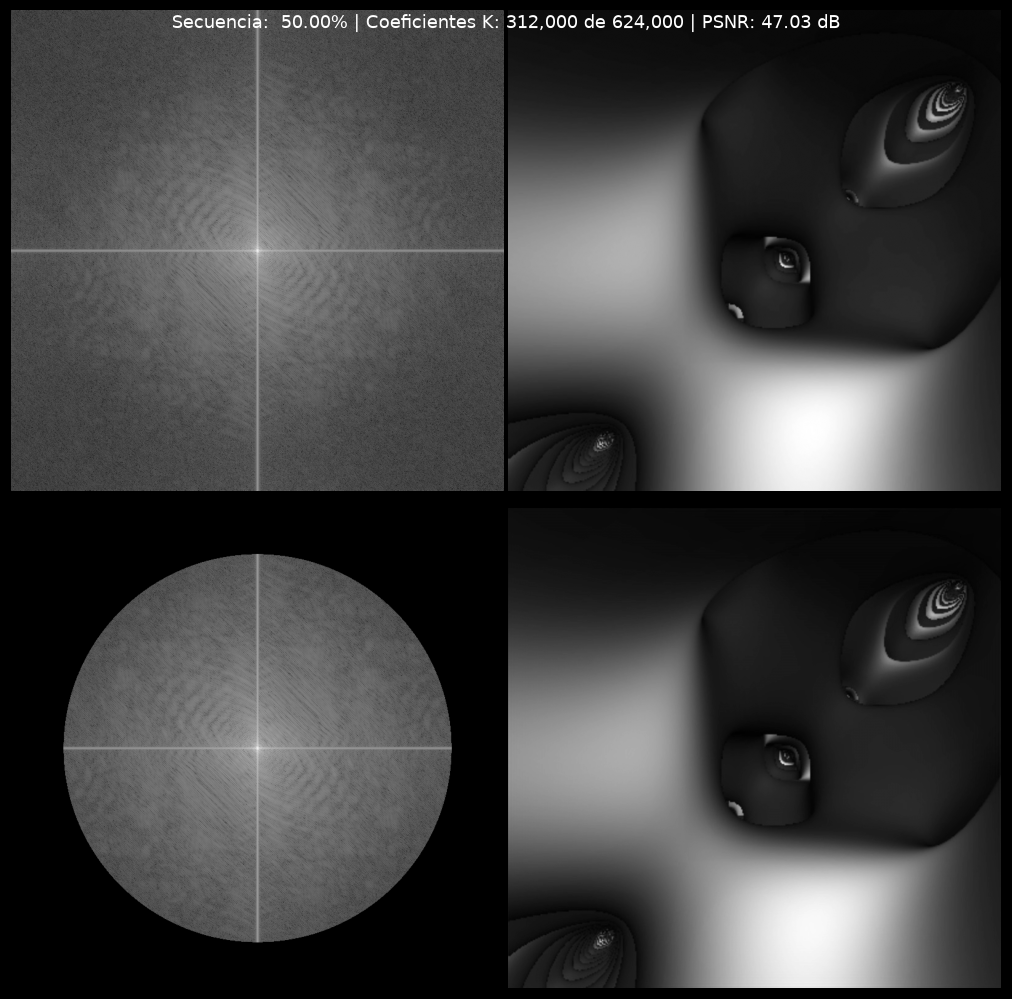

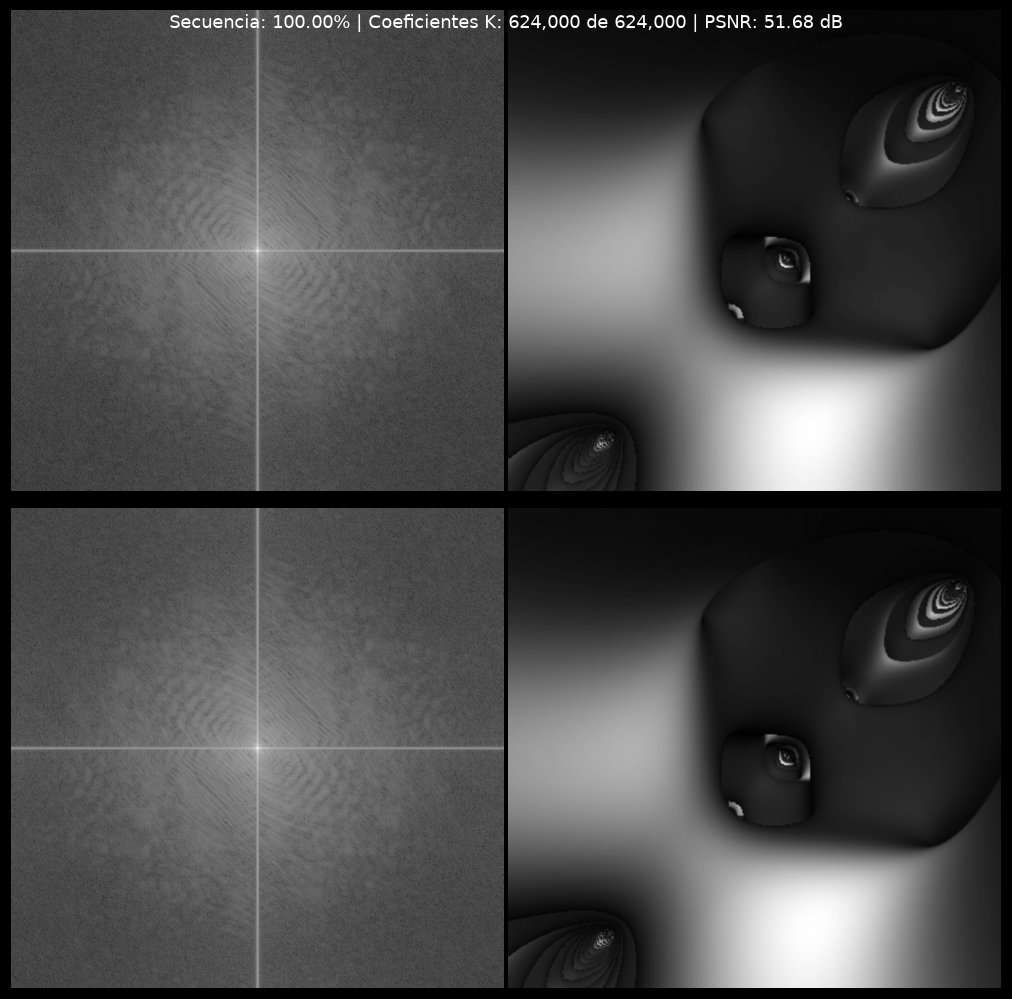

In [17]:
# Demostración estática pre-renderizada en etapas clave de streaming
etapas_progreso = [0.1, 0.5, 2.0, 10.0, 50.0, 100.0]

print("🚀 Generando evidencia visual multi-etapa de la carga progresiva:")
for pct_etapa in etapas_progreso:
    render_progression_2x2(pct_etapa)

## 🎚️ Control Interactivo Dinámico (Slider de Streaming)

Utiliza el siguiente control interactivo para simular el avance de lectura en tiempo real del flujo 1D de coeficientes. Puedes deslizar el porcentaje de transferencia para observar cómo la imagen evoluciona desde una silueta borrosa de frecuencias bajas hasta la nitidez total con micro-texturas.

In [18]:
try:
    from ipywidgets import interact, FloatSlider
    slider_progreso = FloatSlider(
        min=0.05,
        max=100.0,
        step=0.25,
        value=2.0,
        description='% Leído:',
        continuous_update=False,
        readout_format='.2f'
    )
    interact(render_progression_2x2, progreso=slider_progreso);
except ImportError:
    print("⚠️ 'ipywidgets' no está disponible en este entorno. Puedes usar la función render_progression_2x2(pct) manualmente.")

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='% Leído:', min=0.05, step=0…

## 🎯 Conclusiones y Comparativa Técnica con el Experimento 01

| Característica | Experimento 01 (`2026-10-new-format-01.ipynb`) | Experimento 02 (`2026-10-new-format-02.ipynb`) |
| :--- | :--- | :--- |
| **Representación de Datos** | Matriz 2D completa ($H \times W$) modificada con máscara | Secuencia 1D serializada y continua de longitud $H \cdot W$ |
| **Mecanismo de Selección** | Filtro paso bajo sintético (máscara binaria circular $R$) | Ordenamiento radial concéntrico implícito (`np.lexsort`) |
| **Metadatos Requeridos** | Radio $R$, centro $(c_y, c_x)$ y matriz 2D | **Únicamente dimensiones $(H, W)$** |
| **Flujo de Transferencia** | Simulado (corte local de una matriz ya cargada) | **Streaming real** (lectura secuencial de prefijos `secuencia[:K]`) |
| **Eficiencia de Transmisión** | Requiere transferir toda la matriz o máscaras complejas | El decodificador reconstruye en tiempo real con cualquier $K \le N$ |
| **Calidad de Reconstrucción** | Similar visualmente | Idéntica convergencia frecuencial con cero overhead de protocolo |

### Próximos Pasos en `<mx-img />`:
1. **Cuantización y Empaquetado Binario:** Convertir los coeficientes `complex128` a formatos compactos (`float16` o enteros cuantizados para parte real/imaginaria).
2. **Aprovechamiento de Simetría Hermítica:** Dado que la imagen espacial es real, $F(-u, -v) = F^*(u, v)$, lo que permite reducir el volumen de datos a transferir a prácticamente la mitad ($\sim 50\%$).
3. **Transporte de Red en Streaming:** Enviar los fragmentos binarios mediante WebSockets o HTTP Chunked Transfer y decodificar progresivamente en el navegador con Web Workers y WebGL/WebGPU.